# Exploratory Data Analysis: CAISO Cluster 14 and Prior Interconnection Requests

## Purpose
This notebook loads and analyzes **all three workbook sheets**: active, completed, and withdrawn projects. Final outcomes are derived from sheet membership:

- `Completed Generation Projects` → `operational`
- `Withdrawn Generation Projects` → `withdrawn`
- `Grid GenerationQueue` → `active` (unresolved/right-censored)

The valid binary modeling question is whether a newly queued solar project **eventually reaches operation before withdrawal**. This is not equivalent to formal approval versus rejection.

## 1. Imports and data path

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("../Data_ML_SQL/CASIO_Cluster_14_and_Prior_Interconnection_Requests.xlsx")
assert DATA_PATH.exists(), f"Missing data file: {DATA_PATH}"
print("Imports and data path ready.")

Imports and data path ready.


## 2. Load and harmonize every sheet

In [2]:
excel_file = pd.ExcelFile(DATA_PATH)
print("Workbook sheets:", excel_file.sheet_names)

OUTCOME_BY_SHEET = {
    "Grid GenerationQueue": "active",
    "Completed Generation Projects": "operational",
    "Withdrawn Generation Projects": "withdrawn",
}

def snake_case(value):
    value = str(value).replace("\n", " ").strip().lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return value.strip("_")

def load_sheet(sheet_name):
    frame = pd.read_excel(DATA_PATH, sheet_name=sheet_name, skiprows=3)
    frame = frame.loc[:, ~frame.columns.astype(str).str.startswith("Report Run Date")]
    first_col = frame.columns[0]
    valid_name = frame[first_col].notna()
    disclaimer = frame[first_col].astype(str).str.startswith("The contents of these pages")
    frame = frame.loc[valid_name & ~disclaimer].copy()
    frame.columns = [snake_case(col) for col in frame.columns]
    frame = frame.rename(columns={
        "project_name_confidential": "project_name",
        "proposed_on_line_date_as_filed_with_ir": "proposed_online_date",
        "current_on_line_date": "current_online_date",
        "actual_on_line_date": "actual_online_date",
        "interconnection_request_receive_date": "ir_receive_date",
        "study_process": "study_process",
        "net_mws_to_grid": "net_mw_to_grid",
        "full_capacity_partial_or_energy_only_fc_p_eo": "service_type",
        "interconnection_agreement_status": "ia_status",
        "feasibility_study_or_supplemental_review": "feasibility_study",
        "system_impact_study_or_phase_i_cluster_study": "phase1_study",
        "facilities_study_fas_or_phase_ii_cluster_study": "phase2_study",
        "optional_study_os": "optional_study",
        "station_or_transmission_line": "poi_station",
    })
    frame["source_sheet"] = sheet_name
    frame["outcome"] = OUTCOME_BY_SHEET[sheet_name]
    return frame

sheets = {name: load_sheet(name) for name in excel_file.sheet_names}
active = sheets["Grid GenerationQueue"]
completed = sheets["Completed Generation Projects"]
withdrawn = sheets["Withdrawn Generation Projects"]
all_projects = pd.concat(sheets.values(), ignore_index=True, sort=False)

sheet_summary = pd.DataFrame({
    "sheet": list(sheets),
    "clean_projects": [len(sheets[name]) for name in sheets],
    "columns": [sheets[name].shape[1] for name in sheets],
    "outcome": [OUTCOME_BY_SHEET[name] for name in sheets],
})
display(sheet_summary)
print(f"Combined projects: {len(all_projects):,}")

Workbook sheets: ['Grid GenerationQueue', 'Completed Generation Projects', 'Withdrawn Generation Projects']


,sheet,clean_projects,columns,outcome
0,Grid GenerationQueue,262,35,active
1,Completed Generation Projects,252,34,operational
2,Withdrawn Generation Projects,1764,33,withdrawn


Combined projects: 2,278


## 3. Schema alignment, dates, and engineered fields

In [3]:
date_cols = [
    "ir_receive_date", "queue_date", "proposed_online_date",
    "current_online_date", "actual_online_date", "withdrawn_date"
]
numeric_cols = ["mw_1", "mw_2", "mw_3", "net_mw_to_grid", "tpd_allocation_percentage"]

for col in date_cols:
    if col not in all_projects:
        all_projects[col] = pd.NaT
    all_projects[col] = pd.to_datetime(all_projects[col], errors="coerce")

for col in numeric_cols:
    if col not in all_projects:
        all_projects[col] = np.nan
    all_projects[col] = pd.to_numeric(all_projects[col], errors="coerce")

all_projects["queue_year"] = all_projects["queue_date"].dt.year
all_projects["component_mw_sum"] = all_projects[["mw_1", "mw_2", "mw_3"]].fillna(0).sum(axis=1)
all_projects["is_hybrid"] = all_projects[["type_2", "type_3", "fuel_2", "fuel_3"]].notna().any(axis=1)
all_projects["days_ir_to_queue"] = (
    all_projects["queue_date"] - all_projects["ir_receive_date"]
).dt.days
all_projects["days_queue_to_proposed"] = (
    all_projects["proposed_online_date"] - all_projects["queue_date"]
).dt.days
all_projects["days_queue_to_operation"] = (
    all_projects["actual_online_date"] - all_projects["queue_date"]
).dt.days
all_projects["days_queue_to_withdrawal"] = (
    all_projects["withdrawn_date"] - all_projects["queue_date"]
).dt.days

resolved = all_projects[all_projects["outcome"].isin(["operational", "withdrawn"])].copy()
resolved["reached_operation"] = (resolved["outcome"] == "operational").astype(int)
c14 = all_projects[all_projects["study_process"].astype(str).str.strip().eq("C14")].copy()

print(f"Resolved cohort: {len(resolved):,}")
print(f"C14-only cohort: {len(c14):,}")
display(pd.crosstab(c14["outcome"], c14["study_process"]))

Resolved cohort: 2,016
C14-only cohort: 359


study_process,C14
outcome,
active,104
withdrawn,255


## 4. Data quality by worksheet

In [4]:
quality_rows = []
for name, frame in sheets.items():
    quality_rows.append({
        "sheet": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "exact_duplicate_rows": frame.duplicated().sum(),
        "duplicate_queue_positions": frame["queue_position"].duplicated().sum(),
        "missing_cells_pct": frame.isna().mean().mean() * 100,
    })
quality_by_sheet = pd.DataFrame(quality_rows)
display(quality_by_sheet.round(2))

shared_cols = sorted(set.intersection(*(set(frame.columns) for frame in sheets.values())))
schema_matrix = pd.DataFrame({
    name: [col in frame.columns for col in sorted(set().union(*(set(x.columns) for x in sheets.values())))]
    for name, frame in sheets.items()
}, index=sorted(set().union(*(set(x.columns) for x in sheets.values()))))
print(f"Shared columns across all sheets: {len(shared_cols)}")
display(schema_matrix[~schema_matrix.all(axis=1)])

,sheet,rows,columns,exact_duplicate_rows,duplicate_queue_positions,missing_cells_pct
0,Grid GenerationQueue,262,35,0,0,24.92
1,Completed Generation Projects,252,34,0,0,29.75
2,Withdrawn Generation Projects,1764,33,0,0,34.28


Shared columns across all sheets: 30


,Grid GenerationQueue,Completed Generation Projects,Withdrawn Generation Projects
actual_online_date,False,True,False
current_online_date,True,False,True
pto_study_region,True,True,False
reason_for_withdrawal,False,False,True
suspension_status,True,False,False
tpd_allocation_group,True,True,False
tpd_allocation_percentage,True,True,False
withdrawn_date,False,False,True


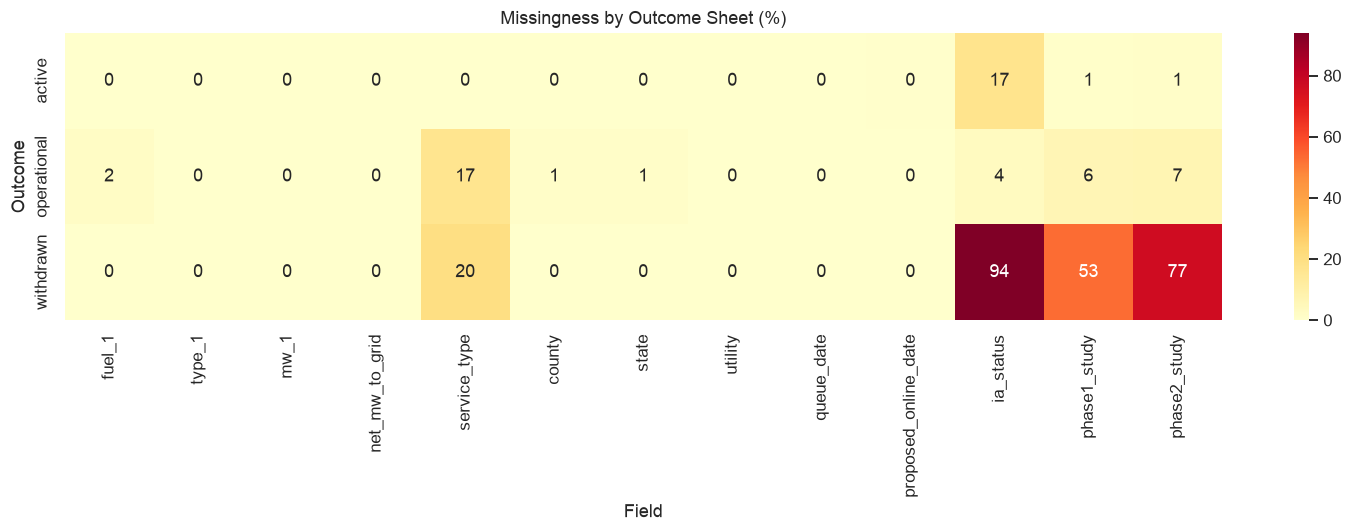

In [5]:
important_cols = [
    "fuel_1", "type_1", "mw_1", "net_mw_to_grid", "service_type",
    "county", "state", "utility", "queue_date", "proposed_online_date",
    "ia_status", "phase1_study", "phase2_study"
]
missing_matrix = pd.DataFrame({
    outcome: all_projects.loc[all_projects["outcome"] == outcome, important_cols]
                         .isna().mean() * 100
    for outcome in ["active", "operational", "withdrawn"]
}).T

plt.figure(figsize=(14, 5))
sns.heatmap(missing_matrix, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Missingness by Outcome Sheet (%)")
plt.xlabel("Field")
plt.ylabel("Outcome")
plt.tight_layout()
plt.show()

## 5. Outcome construction and imbalance

The `application_status` column is redundant with sheet membership. `ia_status` is not the target: some withdrawn projects have executed agreements, and an executed agreement does not prove that a project reached operation.

All-sheet outcome counts:


,projects
outcome,
operational,252
withdrawn,1764
active,262


Operational share among resolved: 12.50%
Class ratio withdrawn:operational = 7.00:1


ia_status,Executed,Filed Unexecuted,In Progress,Missing,Terminated
outcome,,,,,
active,211,1,5,45,0
operational,241,1,1,9,0
withdrawn,66,0,32,1656,10


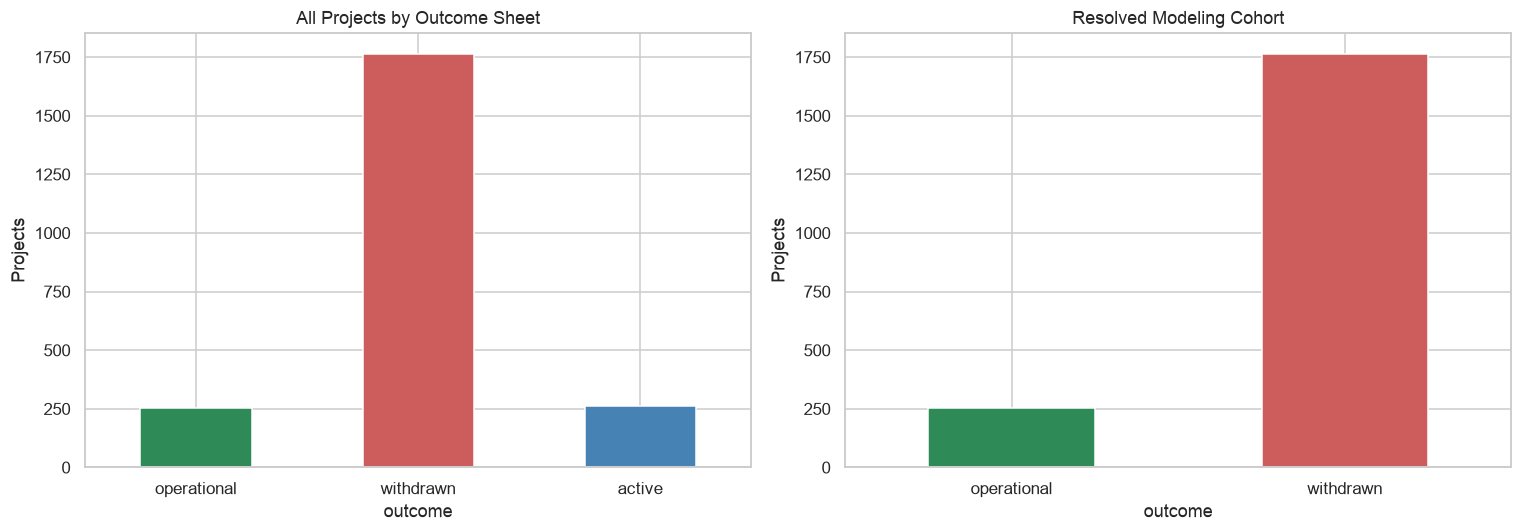

In [6]:
outcome_counts = all_projects["outcome"].value_counts().reindex(
    ["operational", "withdrawn", "active"], fill_value=0
)
resolved_counts = resolved["outcome"].value_counts()

print("All-sheet outcome counts:")
display(outcome_counts.to_frame("projects"))
print(f"Operational share among resolved: {resolved['reached_operation'].mean():.2%}")
print(f"Class ratio withdrawn:operational = "
      f"{resolved_counts.get('withdrawn', 0) / resolved_counts.get('operational', 1):.2f}:1")

ia_by_outcome = pd.crosstab(
    all_projects["outcome"], all_projects["ia_status"].fillna("Missing")
)
display(ia_by_outcome)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
outcome_counts.plot.bar(ax=axes[0], color=["seagreen", "indianred", "steelblue"])
axes[0].set_title("All Projects by Outcome Sheet")
axes[0].set_ylabel("Projects")
axes[0].tick_params(axis="x", rotation=0)

resolved_counts.reindex(["operational", "withdrawn"]).plot.bar(
    ax=axes[1], color=["seagreen", "indianred"]
)
axes[1].set_title("Resolved Modeling Cohort")
axes[1].set_ylabel("Projects")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Numerical and probability-distribution diagnostics

,feature,n,mean,median,std,min,max,skew,kurtosis
0,net_mw_to_grid,2278,216.07,126.25,270.33,0.0,3200.0,3.35,18.97
1,days_queue_to_proposed,2277,1309.20,1311.00,528.92,-5842.0,4961.0,-0.45,16.78
2,days_queue_to_operation,239,2361.03,2248.00,1158.33,-117.0,5779.0,0.52,0.33
3,days_queue_to_withdrawal,1725,658.29,368.00,707.79,-5.0,5285.0,2.31,7.11


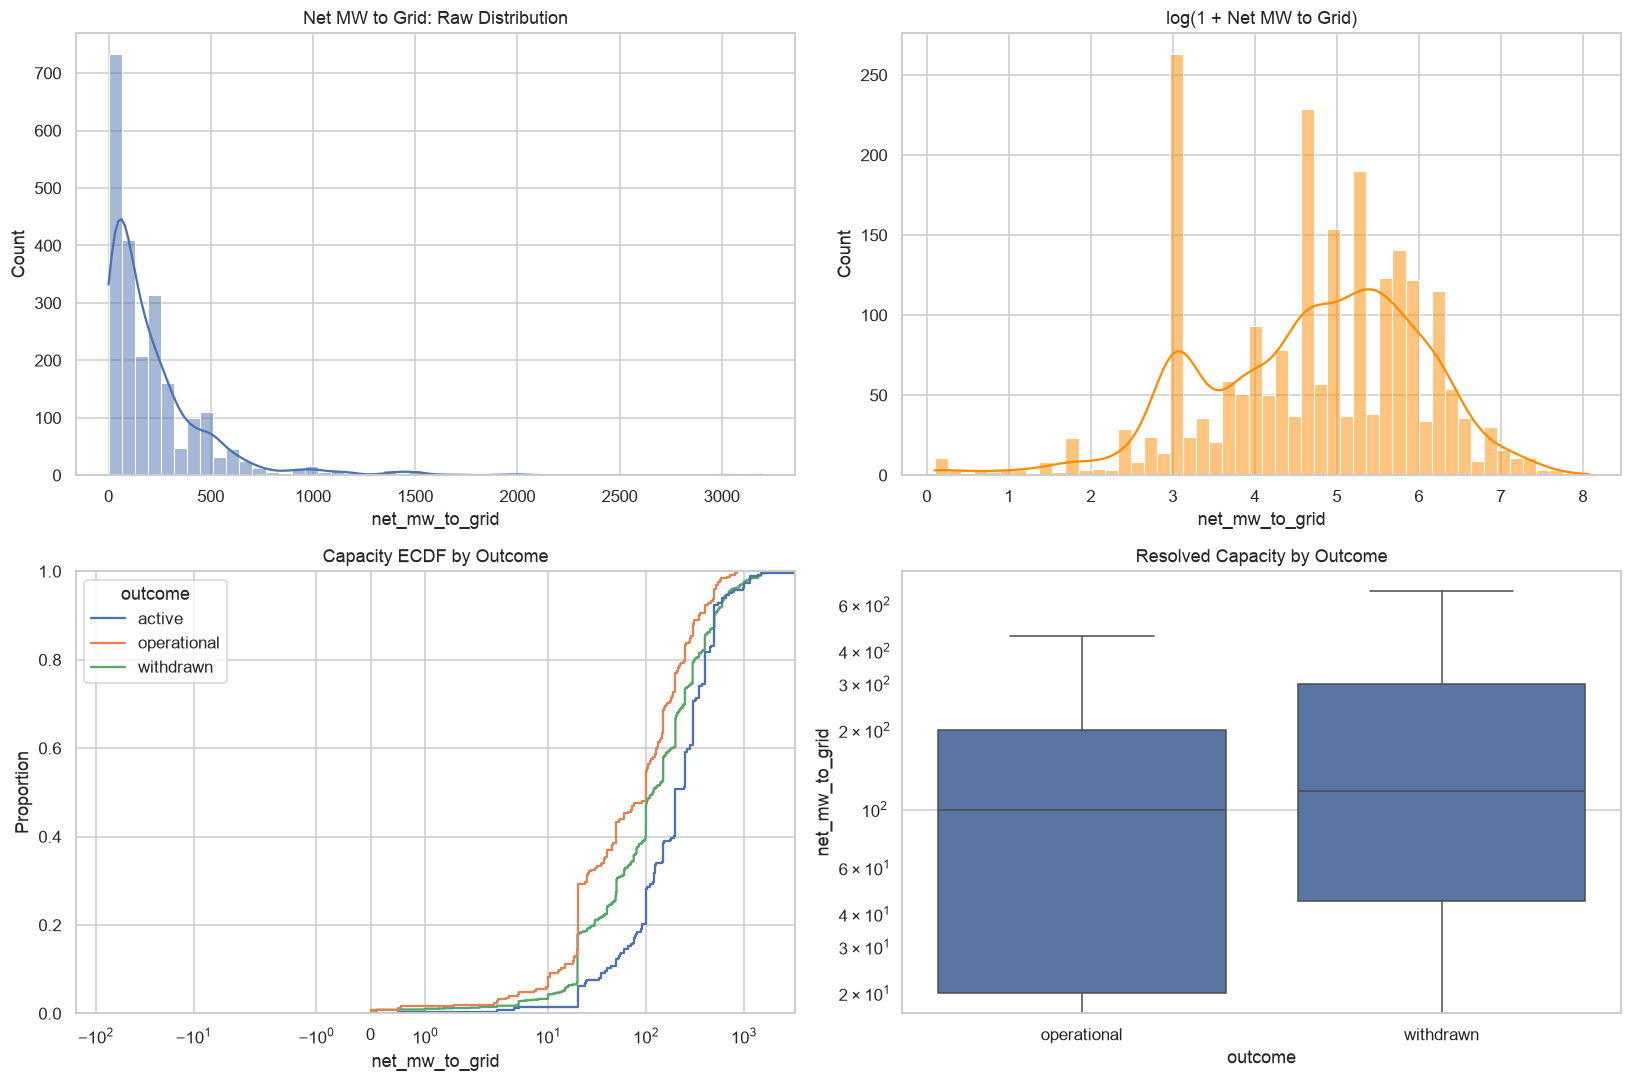

In [7]:
def summarize_numeric(data, col):
    x = pd.to_numeric(data[col], errors="coerce").dropna()
    return {
        "feature": col,
        "n": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "min": x.min(),
        "max": x.max(),
        "skew": stats.skew(x, nan_policy="omit") if len(x) > 2 else np.nan,
        "kurtosis": stats.kurtosis(x, nan_policy="omit") if len(x) > 3 else np.nan,
    }

numeric_summary = pd.DataFrame([
    summarize_numeric(all_projects, "net_mw_to_grid"),
    summarize_numeric(all_projects, "days_queue_to_proposed"),
    summarize_numeric(all_projects, "days_queue_to_operation"),
    summarize_numeric(all_projects, "days_queue_to_withdrawal"),
])
display(numeric_summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(all_projects["net_mw_to_grid"], bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Net MW to Grid: Raw Distribution")

positive_mw = all_projects.loc[all_projects["net_mw_to_grid"] > 0, "net_mw_to_grid"]
sns.histplot(np.log1p(positive_mw), bins=50, kde=True, color="darkorange", ax=axes[0, 1])
axes[0, 1].set_title("log(1 + Net MW to Grid)")

sns.ecdfplot(data=all_projects, x="net_mw_to_grid", hue="outcome", ax=axes[1, 0])
axes[1, 0].set_xscale("symlog")
axes[1, 0].set_title("Capacity ECDF by Outcome")

sns.boxplot(data=resolved, x="outcome", y="net_mw_to_grid",
            order=["operational", "withdrawn"], showfliers=False, ax=axes[1, 1])
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Resolved Capacity by Outcome")
plt.tight_layout()
plt.show()

## 7. Technology, service type, and geography

,count,operational_rate
fuel_1,,
Solar,964,0.139004
Battery,528,0.083333
Natural Gas,242,0.148760
Wind Turbine,190,0.105263
Geothermal,33,0.030303
Biofuel,21,0.380952
Water,13,0.153846


,count,operational_rate
service_type,,
Full Capacity,1343,0.122859
NaN,396,0.106061
Energy Only,237,0.080169
Partial Capacity,40,0.650000


,count,operational_rate
utility,,
PGAE,959,0.120959
SCE,712,0.113764
SDGE,296,0.175676
VEA,21,0.047619


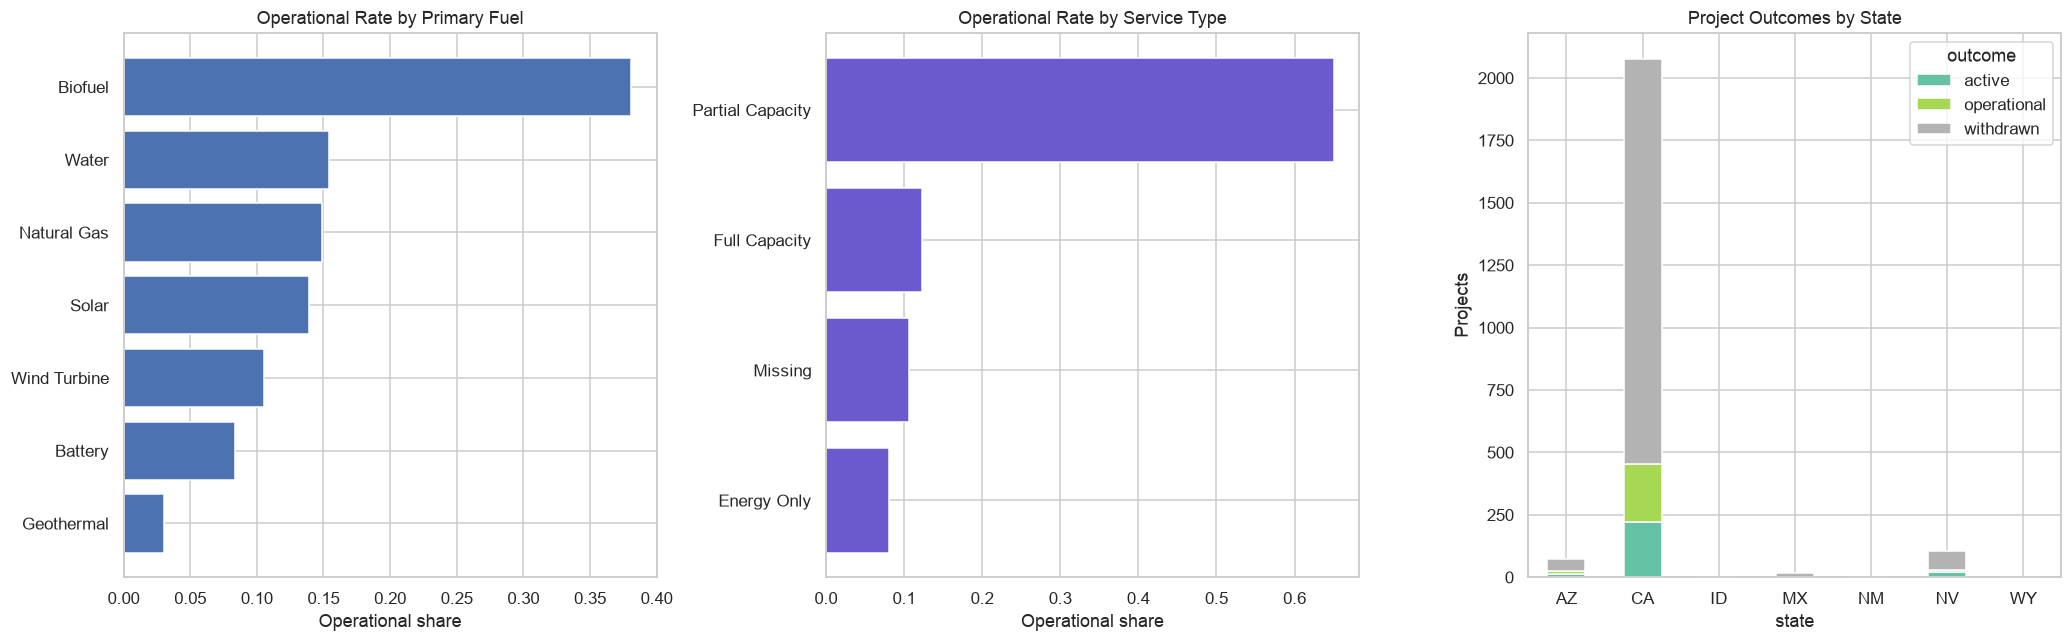

In [8]:
def outcome_rate(data, group_col, min_count=10):
    table = (
        data.groupby(group_col, dropna=False)["reached_operation"]
            .agg(["count", "mean"])
            .rename(columns={"mean": "operational_rate"})
    )
    return table[table["count"] >= min_count].sort_values("count", ascending=False)

fuel_rates = outcome_rate(resolved, "fuel_1")
service_rates = outcome_rate(resolved, "service_type")
utility_rates = outcome_rate(resolved, "utility", min_count=20)

display(fuel_rates)
display(service_rates)
display(utility_rates)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fuel_plot = fuel_rates.sort_values("operational_rate")
axes[0].barh(fuel_plot.index.astype(str), fuel_plot["operational_rate"])
axes[0].set_title("Operational Rate by Primary Fuel")
axes[0].set_xlabel("Operational share")

service_plot = service_rates.sort_values("operational_rate")
service_labels = ["Missing" if pd.isna(x) else str(x) for x in service_plot.index]
axes[1].barh(service_labels, service_plot["operational_rate"], color="slateblue")
axes[1].set_title("Operational Rate by Service Type")
axes[1].set_xlabel("Operational share")

state_counts = pd.crosstab(all_projects["state"], all_projects["outcome"])
state_counts.plot.bar(stacked=True, ax=axes[2], colormap="Set2")
axes[2].set_title("Project Outcomes by State")
axes[2].set_ylabel("Projects")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 8. Solar and wind projects

,count,operational,operational_rate
fuel_1,,,
Solar,964,134,0.139004
Wind Turbine,190,20,0.105263


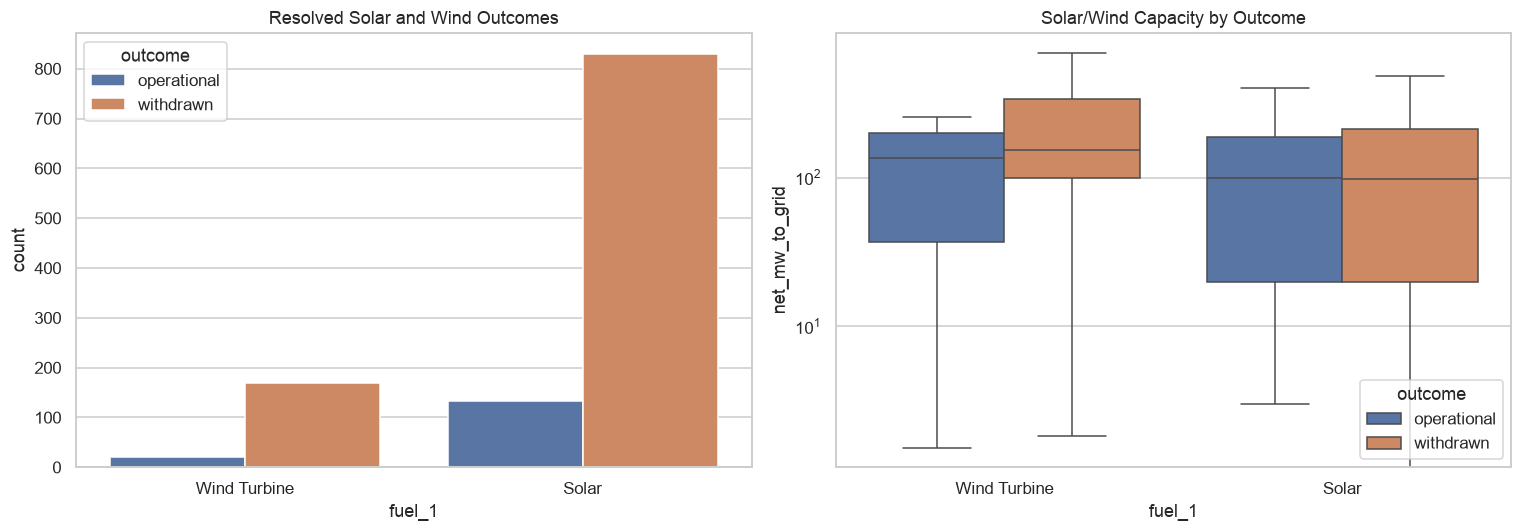

In [9]:
solar_wind = resolved[resolved["fuel_1"].isin(["Solar", "Wind Turbine"])].copy()
solar_wind_summary = (
    solar_wind.groupby("fuel_1")["reached_operation"]
              .agg(["count", "sum", "mean"])
              .rename(columns={"sum": "operational", "mean": "operational_rate"})
)
display(solar_wind_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=solar_wind, x="fuel_1", hue="outcome",
              hue_order=["operational", "withdrawn"], ax=axes[0])
axes[0].set_title("Resolved Solar and Wind Outcomes")

sns.boxplot(data=solar_wind, x="fuel_1", y="net_mw_to_grid",
            hue="outcome", showfliers=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Solar/Wind Capacity by Outcome")
plt.tight_layout()
plt.show()

## 9. Temporal outcomes and event times

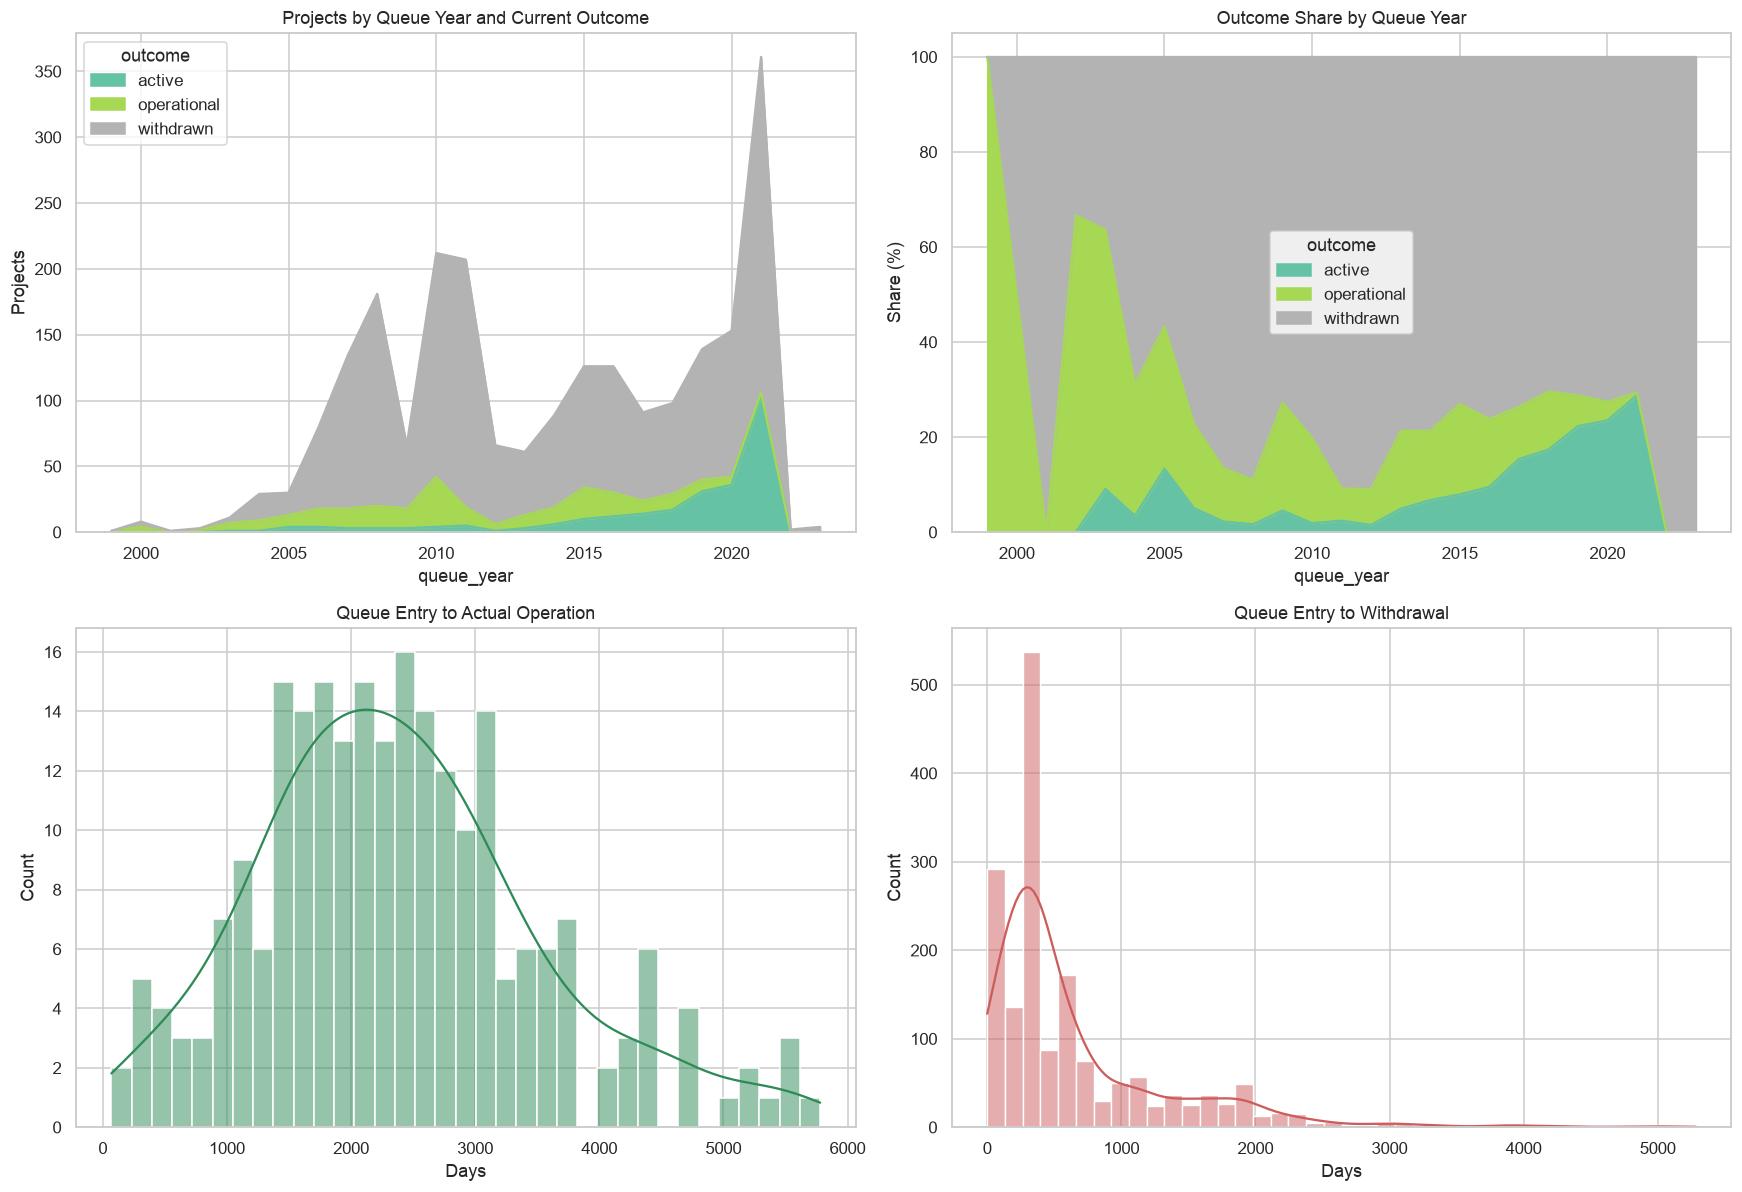

In [10]:
year_status = pd.crosstab(all_projects["queue_year"], all_projects["outcome"])
year_share = pd.crosstab(
    all_projects["queue_year"], all_projects["outcome"], normalize="index"
) * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
year_status.plot.area(stacked=True, ax=axes[0, 0], colormap="Set2")
axes[0, 0].set_title("Projects by Queue Year and Current Outcome")
axes[0, 0].set_ylabel("Projects")

year_share.plot.area(stacked=True, ax=axes[0, 1], colormap="Set2")
axes[0, 1].set_title("Outcome Share by Queue Year")
axes[0, 1].set_ylabel("Share (%)")

operation_days = completed["actual_online_date"] if "actual_online_date" in completed else pd.Series(dtype=float)
operation_days = (
    pd.to_datetime(operation_days, errors="coerce")
    - pd.to_datetime(completed["queue_date"], errors="coerce")
).dt.days
operation_days = operation_days[operation_days >= 0]
sns.histplot(operation_days, bins=35, kde=True, color="seagreen", ax=axes[1, 0])
axes[1, 0].set_title("Queue Entry to Actual Operation")
axes[1, 0].set_xlabel("Days")

withdrawal_days = all_projects.loc[
    (all_projects["outcome"] == "withdrawn")
    & (all_projects["days_queue_to_withdrawal"] >= 0),
    "days_queue_to_withdrawal",
]
sns.histplot(withdrawal_days, bins=40, kde=True, color="indianred", ax=axes[1, 1])
axes[1, 1].set_title("Queue Entry to Withdrawal")
axes[1, 1].set_xlabel("Days")
plt.tight_layout()
plt.show()

## 10. Withdrawal reasons and limits on causal claims

,projects
reason_for_withdrawal,
NaN,1078
IC Request,620
Failure to Cure Deficiency,64
FERC Order,2


Withdrawal reason populated: 38.9%


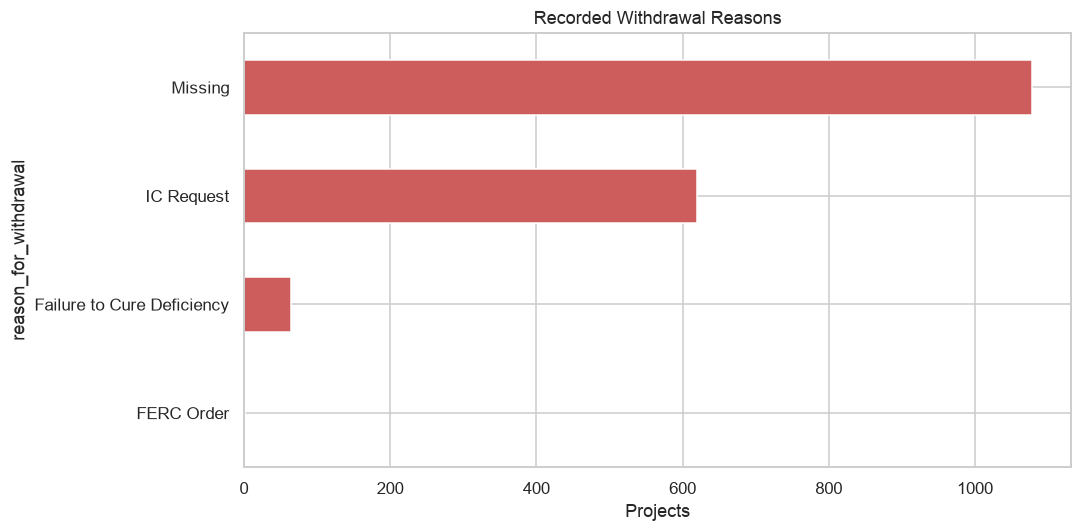

In [11]:
reason_counts = withdrawn["reason_for_withdrawal"].value_counts(dropna=False)
display(reason_counts.to_frame("projects"))

known_reason_pct = withdrawn["reason_for_withdrawal"].notna().mean()
print(f"Withdrawal reason populated: {known_reason_pct:.1%}")

fig, ax = plt.subplots(figsize=(10, 5))
plot_reasons = reason_counts.rename(index={np.nan: "Missing"})
plot_reasons.sort_values().plot.barh(ax=ax, color="indianred")
ax.set_title("Recorded Withdrawal Reasons")
ax.set_xlabel("Projects")
plt.tight_layout()
plt.show()

The available withdrawal reasons are sparse and broad. Differences by fuel, size, service type, or utility can identify predictive associations, but they cannot establish *why* a project withdrew. Upgrade costs, financing, permitting, study findings, developer strategy, and local grid constraints are mostly absent.

## 11. Study and agreement fields: useful descriptively, dangerous predictively

In [12]:
milestone_cols = ["feasibility_study", "phase1_study", "phase2_study", "ia_status"]
for col in milestone_cols:
    print(f"\n{col}")
    display(pd.crosstab(all_projects["outcome"], all_projects[col].fillna("Missing")))


feasibility_study


feasibility_study,Missing,Offered,Required,System Impact Study,Waived
outcome,,,,,
active,254,0,0,0,8
operational,223,2,12,1,14
withdrawn,1545,1,150,2,66



phase1_study


phase1_study,Complete,Facilities Study,Missing,Re-Study,Unexpected,Waived
outcome,,,,,,
active,258,2,2,0,0,0
operational,214,19,16,2,1,0
withdrawn,791,28,937,7,0,1



phase2_study


phase2_study,Complete,Missing,Re-Study,SGIA,Withdrawn
outcome,,,,,
active,255,3,2,2,0
operational,211,17,4,20,0
withdrawn,380,1350,7,26,1



ia_status


ia_status,Executed,Filed Unexecuted,In Progress,Missing,Terminated
outcome,,,,,
active,211,1,5,45,0
operational,241,1,1,9,0
withdrawn,66,0,32,1656,10


These milestone fields describe the latest observed process state and often occur after queue entry. They should be excluded from an **at-submission** risk model. A separate “current-stage” model may use them only if prediction time is explicitly defined and historical point-in-time values are available.

## 12. C14-specific cohort

,projects,share
outcome,,
withdrawn,255,0.710306
active,104,0.289694


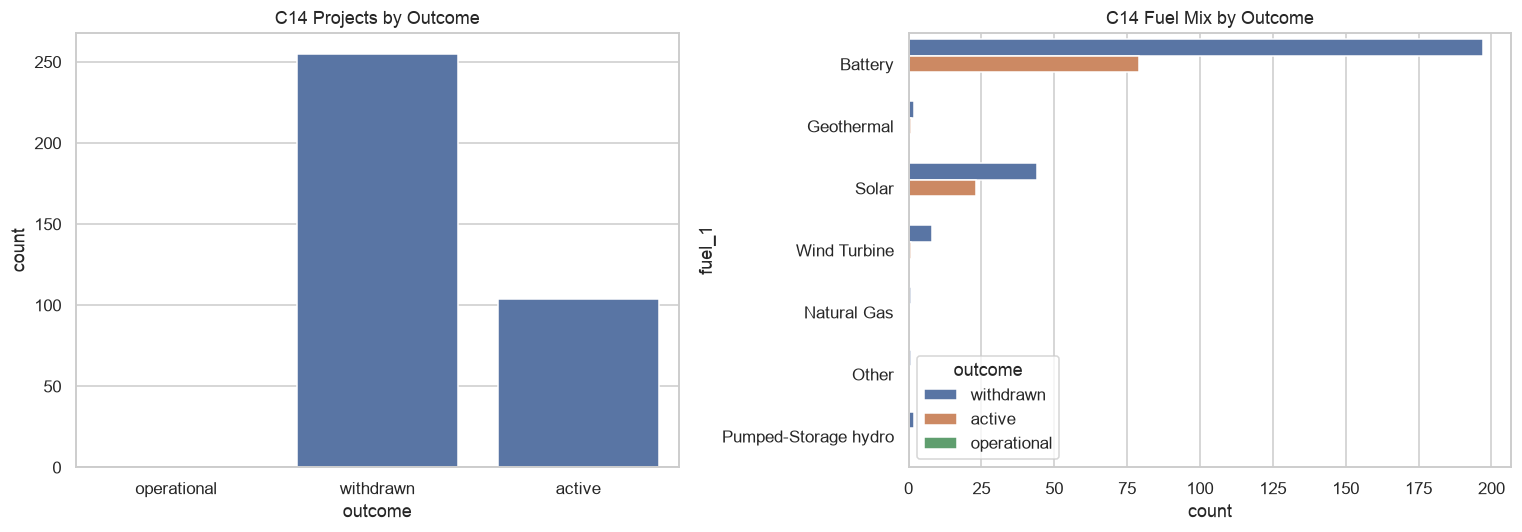

In [13]:
c14_summary = pd.DataFrame({
    "projects": c14["outcome"].value_counts(),
    "share": c14["outcome"].value_counts(normalize=True),
})
display(c14_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=c14, x="outcome",
              order=["operational", "withdrawn", "active"], ax=axes[0])
axes[0].set_title("C14 Projects by Outcome")

sns.countplot(data=c14, y="fuel_1", hue="outcome",
              hue_order=["withdrawn", "active", "operational"], ax=axes[1])
axes[1].set_title("C14 Fuel Mix by Outcome")
plt.tight_layout()
plt.show()

## 13. Queue-entry feature policy

In [14]:
feature_policy = pd.DataFrame([
    ("queue_date, ir_receive_date, study_process", "Use", "Known at queue entry"),
    ("type_1/2/3, fuel_1/2/3", "Use", "Technology and hybrid design"),
    ("mw_1/2/3, net_mw_to_grid", "Use", "Requested capacity"),
    ("service_type, county, state, utility, poi_station", "Use/encode carefully", "Application context; some high cardinality"),
    ("proposed_online_date", "Use derived horizon", "Requested at filing; validate date quality"),
    ("application_status, source_sheet, outcome", "Target only", "Directly encode the outcome"),
    ("withdrawn_date, reason_for_withdrawal", "Exclude", "Direct withdrawal leakage"),
    ("actual_online_date, current_online_date", "Exclude", "Post-outcome leakage"),
    ("ia_status, phase/study status", "Exclude at submission", "Latest process milestones"),
    ("tpd allocation fields", "Exclude unless point-in-time", "Missing structurally on withdrawn sheet"),
], columns=["feature_group", "policy", "reason"])
display(feature_policy)

,feature_group,policy,reason
0,"queue_date, ir_receive_date, study_process",Use,Known at queue entry
1,"type_1/2/3, fuel_1/2/3",Use,Technology and hybrid design
2,"mw_1/2/3, net_mw_to_grid",Use,Requested capacity
3,"service_type, county, state, utility, poi_station",Use/encode carefully,Application context; some high cardinality
4,proposed_online_date,Use derived horizon,Requested at filing; validate date quality
5,"application_status, source_sheet, outcome",Target only,Directly encode the outcome
6,"withdrawn_date, reason_for_withdrawal",Exclude,Direct withdrawal leakage
7,"actual_online_date, current_online_date",Exclude,Post-outcome leakage
8,"ia_status, phase/study status",Exclude at submission,Latest process milestones
9,tpd allocation fields,Exclude unless point-in-time,Missing structurally on withdrawn sheet


## 14. Final assessment

### ML usefulness
This workbook is useful when all three sheets are combined:

- **2,016 resolved projects** provide direct CAISO `operational` versus `withdrawn` labels.
- Active projects remain unresolved and should not be labeled as successful.
- The resolved data are substantially imbalanced, so accuracy alone is misleading.
- The workbook is valuable for CAISO-specific EDA, withdrawal reasons, current queue context, and future inference.

### Recommended role
Use Berkeley Lab as the canonical modeling source because it is larger and historically harmonized. Use this direct CAISO workbook to validate source records, enrich CAISO-specific fields, inspect withdrawal reasons, and test temporal/domain shift. Do not append it to Berkeley without project-level deduplication because the sources overlap.

### Modeling recommendation
1. Primary model: calibrated classifier for `operational` versus `withdrawn`, trained only on resolved records and evaluated with temporal holdouts, PR-AUC, recall/precision, Brier score, and calibration.
2. Optional second model: competing-risks survival model for time to operation versus withdrawal, retaining active projects as right-censored observations.
3. Report “probability of reaching operation before withdrawal,” not formal acceptance/rejection probability.